In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from PIL import Image
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.resnet50 import preprocess_input

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
model = load_model("../models/resnet50_fine_tuned.keras")

print("Fine-Tuned Model Loaded Successfully!")
print("Total Layers:", len(model.layers))

Fine-Tuned Model Loaded Successfully!
Total Layers: 179


In [5]:
for layer in model.layers[-30:]:
    print(layer.name)

conv5_block1_0_conv
conv5_block1_3_conv
conv5_block1_0_bn
conv5_block1_3_bn
conv5_block1_add
conv5_block1_out
conv5_block2_1_conv
conv5_block2_1_bn
conv5_block2_1_relu
conv5_block2_2_conv
conv5_block2_2_bn
conv5_block2_2_relu
conv5_block2_3_conv
conv5_block2_3_bn
conv5_block2_add
conv5_block2_out
conv5_block3_1_conv
conv5_block3_1_bn
conv5_block3_1_relu
conv5_block3_2_conv
conv5_block3_2_bn
conv5_block3_2_relu
conv5_block3_3_conv
conv5_block3_3_bn
conv5_block3_add
conv5_block3_out
global_average_pooling2d
dense
dropout
dense_1


In [6]:
last_conv_layer = model.get_layer("conv5_block3_out")

grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        last_conv_layer.output,
        model.output
    ]
)

print("Grad-CAM Model Created Successfully!")
print("Selected Layer:", last_conv_layer.name)

Grad-CAM Model Created Successfully!
Selected Layer: conv5_block3_out


In [7]:
def make_gradcam_heatmap(img_array, grad_model):

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img_array)

        predicted_class = tf.argmax(predictions[0])

        class_output = predictions[:, predicted_class]

    grads = tape.gradient(class_output, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)

    return heatmap.numpy()

print("Grad-CAM function created successfully!")

Grad-CAM function created successfully!


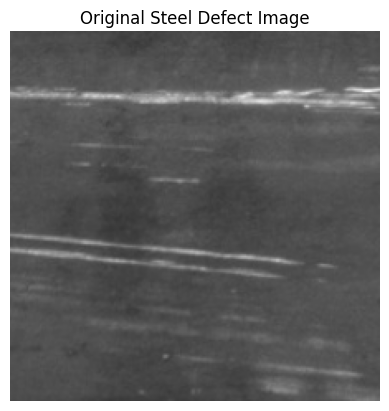

Image loaded successfully!
Image Name: scratches_241.jpg
Image Shape: (224, 224, 3)


In [8]:
dataset_path = "../data/raw/NEU-DET"

image_path = os.path.join(
    dataset_path,
    "validation",
    "Images",
    "scratches"
)

image_name = os.listdir(image_path)[0]

full_image_path = os.path.join(image_path, image_name)

img = Image.open(full_image_path).convert("RGB")

img = img.resize((224, 224))

img_array = np.array(img)

plt.imshow(img)
plt.title("Original Steel Defect Image")
plt.axis("off")
plt.show()

print("Image loaded successfully!")
print("Image Name:", image_name)
print("Image Shape:", img_array.shape)

In [9]:
classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

In [10]:
input_image = np.expand_dims(img_array, axis=0)

input_image = preprocess_input(input_image)

predictions = model.predict(input_image)

predicted_index = np.argmax(predictions[0])

predicted_label = classes[predicted_index]

confidence = predictions[0][predicted_index] * 100

print("Predicted Defect:", predicted_label)
print("Confidence:", confidence, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Defect: scratches
Confidence: 99.99991 %


C:\Users\salun\AppData\Roaming\Python\Python314\site-packages\keras\src\models\functional.py:291: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


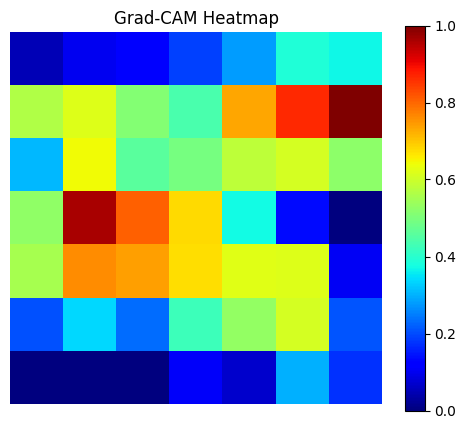

Grad-CAM Heatmap Generated Successfully!


In [11]:
heatmap = make_gradcam_heatmap(input_image, grad_model)

plt.figure(figsize=(6, 5))

plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.colorbar()
plt.axis("off")
plt.show()

print("Grad-CAM Heatmap Generated Successfully!")

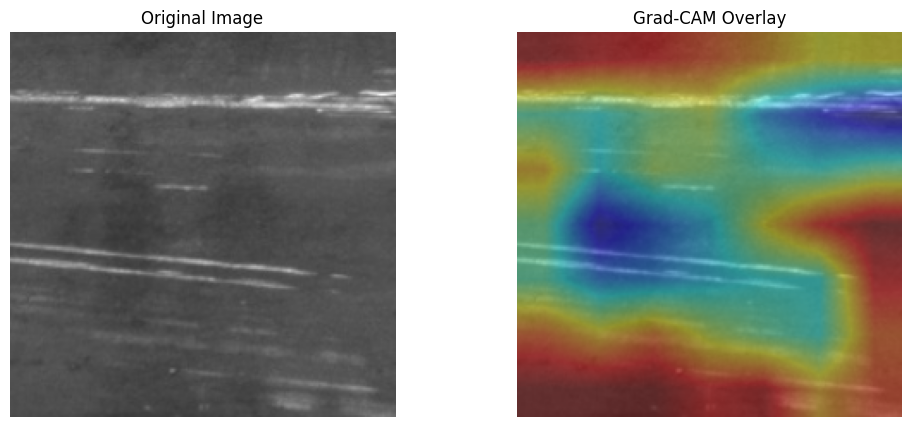

In [12]:
import cv2

# Convert heatmap into image size
heatmap_resized = cv2.resize(
    heatmap,
    (224, 224)
)

# Convert heatmap into RGB colors
heatmap_colored = np.uint8(255 * heatmap_resized)

heatmap_colored = cv2.applyColorMap(
    heatmap_colored,
    cv2.COLORMAP_JET
)

# Combine original image and heatmap
original_image = np.uint8(img_array)

superimposed_img = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Display both images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(superimposed_img)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.show()

In [13]:
os.makedirs("../reports/gradcam", exist_ok=True)

save_path = "../reports/gradcam/scratches_gradcam.png"

cv2.imwrite(save_path, cv2.cvtColor(
    superimposed_img,
    cv2.COLOR_RGB2BGR
))

print("Grad-CAM image saved successfully!")
print("Saved at:", save_path)

Grad-CAM image saved successfully!
Saved at: ../reports/gradcam/scratches_gradcam.png


In [14]:
print("========== GRAD-CAM RESULT ==========")

print("Actual Defect:", "scratches")
print("Predicted Defect:", predicted_label)
print("Confidence:", round(confidence, 2), "%")

print("Heatmap Layer:", last_conv_layer.name)

print("Result Image:", save_path)

print("=====================================")

========== GRAD-CAM RESULT ==========
Actual Defect: scratches
Predicted Defect: scratches
Confidence: 100.0 %
Heatmap Layer: conv5_block3_out
Result Image: ../reports/gradcam/scratches_gradcam.png
